In [14]:
import tensorflow as tf
import numpy as np
import os
from tensorflow.keras.preprocessing import image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


In [15]:
model = tf.keras.models.load_model(
    "mri_parkinson_final.keras",
    custom_objects={"preprocess_input": preprocess_input}
)

print("✅ MRI model loaded successfully")


✅ MRI model loaded successfully


In [16]:
IMG_SIZE = (192, 192)

def preprocess_mri_image(img_path):
    img = image.load_img(img_path, target_size=IMG_SIZE)
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)  # batch dimension
    img_array = preprocess_input(img_array)
    return img_array


In [17]:
img_path = r"D:\predictions\MRI\dataset_split\test\Healthy\Subject1_0.DAT_s1_009.png"

print("Image exists:", os.path.exists(img_path))

input_img = preprocess_mri_image(img_path)


Image exists: True


In [18]:
prediction = model.predict(input_img)
probability = prediction[0][0]

print("Raw probability:", probability)


1/1 [==============================] - 5s 5s/step
Raw probability: 0.14711371


In [19]:
THRESHOLD = 0.4

if probability >= THRESHOLD:
    print("🧠 Prediction: Parkinson’s Disease")
    print(f"Confidence: {probability * 100:.2f}%")
else:
    print("🧠 Prediction: Healthy")
    print(f"Confidence: {(1 - probability) * 100:.2f}%")


🧠 Prediction: Healthy
Confidence: 85.29%


In [20]:
img_path = r"D:\predictions\MRI\dataset_split\test\Healthy\Subject1_1.MRI_3D_Brain_FLAIR_002.png"

print("Image exists:", os.path.exists(img_path))

input_img = preprocess_mri_image(img_path)


Image exists: True


In [21]:
prediction = model.predict(input_img)
probability = prediction[0][0]

print("Raw probability:", probability)


1/1 [==============================] - 1s 519ms/step
Raw probability: 0.68664074


In [22]:
THRESHOLD = 0.4

if probability >= THRESHOLD:
    print("🧠 Prediction: Parkinson’s Disease")
    print(f"Confidence: {probability * 100:.2f}%")
else:
    print("🧠 Prediction: Healthy")
    print(f"Confidence: {(1 - probability) * 100:.2f}%")


🧠 Prediction: Parkinson’s Disease
Confidence: 68.66%


## Confusion Matrix on Test Dataset

In [23]:
import os
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report
from tensorflow.keras.preprocessing import image

# Test dataset paths
TEST_DATA_PATH = r"D:\predictions\MRI\dataset_split\test"
CLASS_NAMES = ["Healthy", "Parkinson"]
IMG_SIZE = (192, 192)

# Collect predictions
true_labels = []
pred_labels = []
pred_probs = []

print("Evaluating test dataset...\n")

for class_idx, class_name in enumerate(CLASS_NAMES):
    class_dir = os.path.join(TEST_DATA_PATH, class_name)
    
    if not os.path.exists(class_dir):
        print(f"[WARNING] Directory not found: {class_dir}")
        continue
    
    files = [f for f in os.listdir(class_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    print(f"[{class_name}] Found {len(files)} images")
    
    for img_file in files:
        img_path = os.path.join(class_dir, img_file)
        try:
            # Load and preprocess image
            img = image.load_img(img_path, target_size=IMG_SIZE)
            img_array = image.img_to_array(img)
            img_array = np.expand_dims(img_array, axis=0)
            img_array = preprocess_input(img_array)
            
            # Make prediction
            prediction = model.predict(img_array, verbose=0)[0][0]
            pred_class = 1 if prediction >= THRESHOLD else 0
            
            true_labels.append(class_idx)
            pred_labels.append(pred_class)
            pred_probs.append(prediction)
        except Exception as e:
            print(f"  [ERROR] {img_file}: {str(e)}")

true_labels = np.array(true_labels)
pred_labels = np.array(pred_labels)
pred_probs = np.array(pred_probs)

print(f"\nTotal images evaluated: {len(true_labels)}\n")


Evaluating test dataset...

[Healthy] Found 1607 images


KeyboardInterrupt: 

In [ ]:
# Compute confusion matrix and metrics
cm = confusion_matrix(true_labels, pred_labels)
acc = accuracy_score(true_labels, pred_labels)
prec = precision_score(true_labels, pred_labels, zero_division=0)
rec = recall_score(true_labels, pred_labels, zero_division=0)
f1 = f1_score(true_labels, pred_labels, zero_division=0)

print("="*70)
print("CONFUSION MATRIX")
print("="*70)
print(f"{'':20} Predicted Healthy  Predicted Parkinson")
print(f"{'Actual Healthy':20} {cm[0,0]:17}  {cm[0,1]:17}")
print(f"{'Actual Parkinson':20} {cm[1,0]:17}  {cm[1,1]:17}")
print("="*70)

print(f"\nPERFORMANCE METRICS:")
print(f"  Accuracy:  {acc:.4f} ({acc*100:.2f}%)")
print(f"  Precision: {prec:.4f} ({prec*100:.2f}%) - of predicted Parkinson, % correct")
print(f"  Recall:    {rec:.4f} ({rec*100:.2f}%) - of actual Parkinson, % detected")
print(f"  F1-Score:  {f1:.4f}")

print(f"\n{'='*70}")
print("CLASSIFICATION REPORT")
print(f"{'='*70}")
print(classification_report(true_labels, pred_labels, target_names=CLASS_NAMES))


CONFUSION MATRIX
                     Predicted Healthy  Predicted Parkinson
Actual Healthy                    1152                455
Actual Parkinson                   290               4705

PERFORMANCE METRICS:
  Accuracy:  0.8872 (88.72%)
  Precision: 0.9118 (91.18%) - of predicted Parkinson, % correct
  Recall:    0.9419 (94.19%) - of actual Parkinson, % detected
  F1-Score:  0.9266

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Healthy       0.80      0.72      0.76      1607
   Parkinson       0.91      0.94      0.93      4995

    accuracy                           0.89      6602
   macro avg       0.86      0.83      0.84      6602
weighted avg       0.88      0.89      0.89      6602



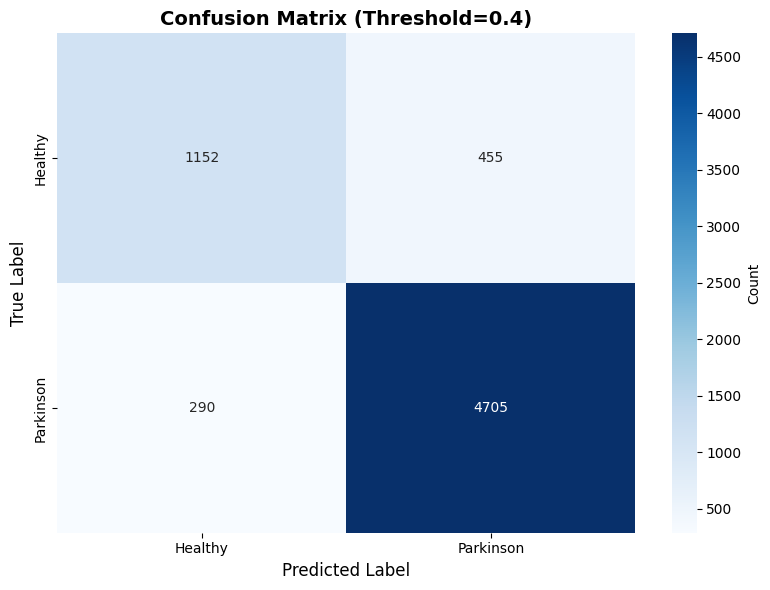


Confusion Matrix Summary:
  True Negatives (TN):  1152
  False Positives (FP): 455
  False Negatives (FN): 290
  True Positives (TP):  4705


In [ ]:
# Visualize confusion matrix
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={'label': 'Count'})
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title(f'Confusion Matrix (Threshold={THRESHOLD})', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"\nConfusion Matrix Summary:")
print(f"  True Negatives (TN):  {cm[0,0]}")
print(f"  False Positives (FP): {cm[0,1]}")
print(f"  False Negatives (FN): {cm[1,0]}")
print(f"  True Positives (TP):  {cm[1,1]}")


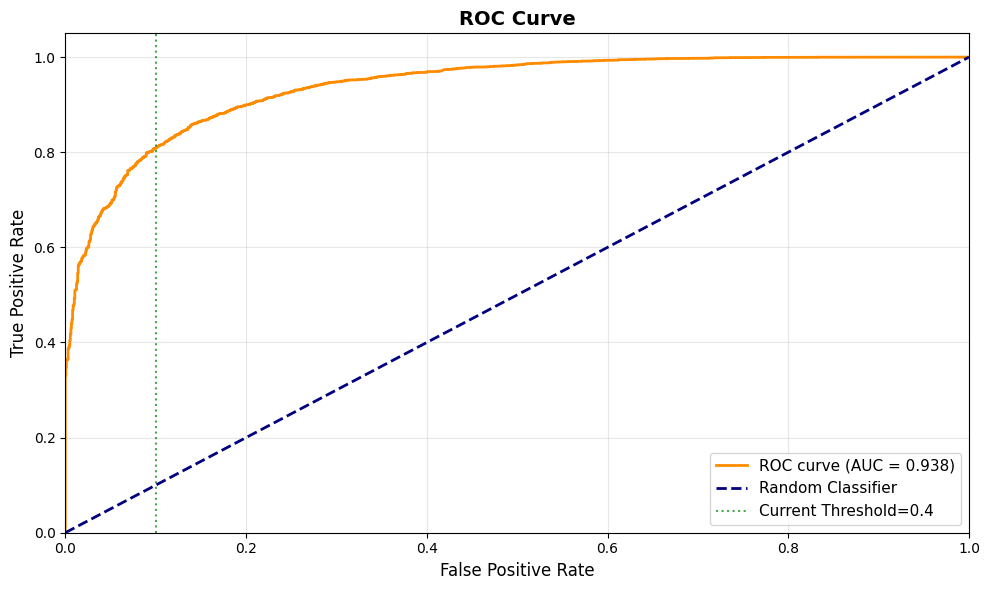


ROC-AUC Score: 0.9378


In [ ]:
# Test different thresholds
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(true_labels, pred_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(10, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Classifier')
plt.axvline(x=0.1, ymin=0, ymax=1, color='green', linestyle=':', alpha=0.7, label=f'Current Threshold={THRESHOLD}')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nROC-AUC Score: {roc_auc:.4f}")
